# Простые контроли, BM25, ALS и содержательные векторы

Сравниваем простые правила, BM25, ALS и готовые векторы. Личная частота оказалась сильным ориентиром, а полный профиль повысил Recall отдельного ALS.

[Описание главы](README.md)

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Импорт работает и без editable install, если notebook открыт внутри репозитория.
root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'pyproject.toml').is_file() and (p / 'research').is_dir())
if str(root / 'src') not in sys.path:
    sys.path.insert(0, str(root / 'src'))
from recsys_lab.presentation import setup_style, save_figure
from recsys_lab.statistics import paired_bootstrap
from recsys_lab.session import ResearchSession
import os
setup_style()

chapter = root / 'research/02_baselines_and_classical'
results = chapter / 'results'
figures = chapter / 'figures'

# saved: результаты первоначального исследования; train: новый рабочий запуск.
MODE = "saved"
RUN_NAME = "reproduction"
RAW_DIR = os.environ.get("T_ECD_RAW")  # Каталог с items.pq и events/.
session = ResearchSession(mode=MODE, run_name=RUN_NAME, raw_dir=RAW_DIR)

def read(name):
    return session.read(chapter.name, name)

registry = pd.read_csv(root / 'results/experiment_registry.csv')

## Запуск этапа

`saved` показывает результаты прежних опытов. Для `train` задайте каталог данных и выполняйте главы по порядку.

In [2]:
# В saved обучение не вызывается. В train выполняется соответствующий этап.
session.run("02_baselines_and_classical")
result_table = session.metrics("02_baselines_and_classical")
if MODE == 'train':
    display(result_table)

Используем сохранённые результаты.


## Результаты экспериментов

## Личная частота товаров

Для каждой пары пользователь–товар берём максимальный вес strong-действия за день, затем суммируем за 60 дней. Выдачу дополняем популярными товарами за 28 дней.

In [3]:
def personal_frequency(events, cutoff_day, half_life=None):
    past = events[(events.day < cutoff_day) & (events.day >= cutoff_day-60) & (events.action >= 2)].copy()
    past['weight'] = past.action.map({2:1.,3:2.,4:3.})
    daily = past.groupby(['u','i','day'], as_index=False).agg(weight=('weight','max'), last_ts=('ts','max'))
    if half_life is not None:
        daily['weight'] *= np.exp2(-(cutoff_day-1-daily.day)/half_life)
    scores = daily.groupby(['u','i'], as_index=False).agg(weight=('weight','sum'), last_ts=('last_ts','max'))
    return scores.sort_values(['u','weight','last_ts','i'], ascending=[True,False,False,True])

def als_confidence(daily_sum):
    # Для implicit передаётся уже готовый confidence, alpha=1.
    return 1. + 20.*np.log1p(daily_sum)

## Сравнение простых методов

Сравниваем recent + pop90 и personal_pop28 на периодах с началом 1279, 1286 и 1293. Внутри каждого периода пользователи и цели одинаковы.

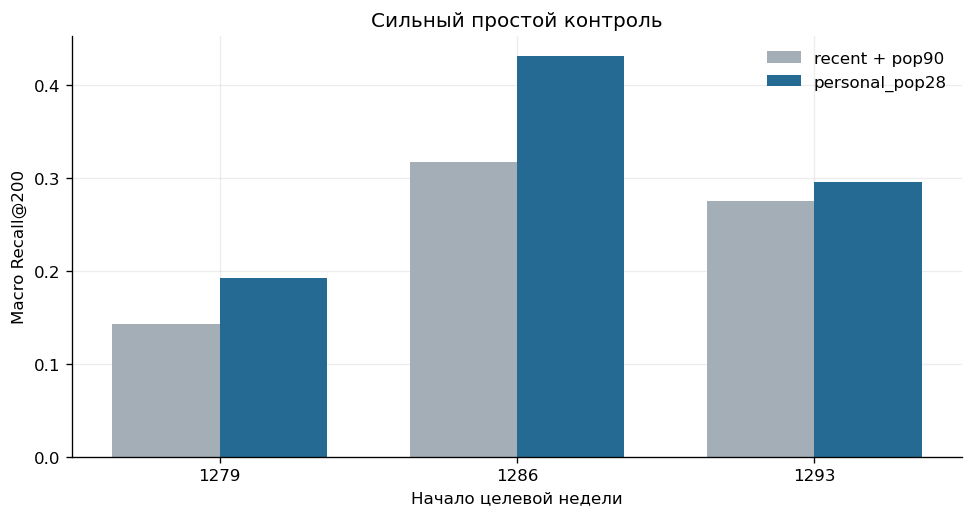

In [4]:
windows = read('temporal_als_20261104__window_summary.csv')
recent = np.array([.1421667,.3170665,.27504864])
fig, ax = plt.subplots(figsize=(8,4.2))
x = np.arange(len(windows))
ax.bar(x-.18, recent, .36, label='recent + pop90', color='#A4AEB6')
ax.bar(x+.18, windows.personal_recall, .36, label='personal_pop28', color='#246A92')
ax.set(xticks=x, xticklabels=windows.anchor.astype(str), ylabel='Macro Recall@200', xlabel='Начало целевой недели', title='Сильный простой контроль')
ax.legend(frameon=False)
save_figure(fig, figures / 'controls_by_window.png')
plt.show()

## Сохранённое сравнение на 1293–1299

Пользователи, каталог, цели и добор pop28 одинаковы. Подготовка и обучение моделей различаются. Численное ограничение ранних нейросетевых запусков описано в приложении MPS.

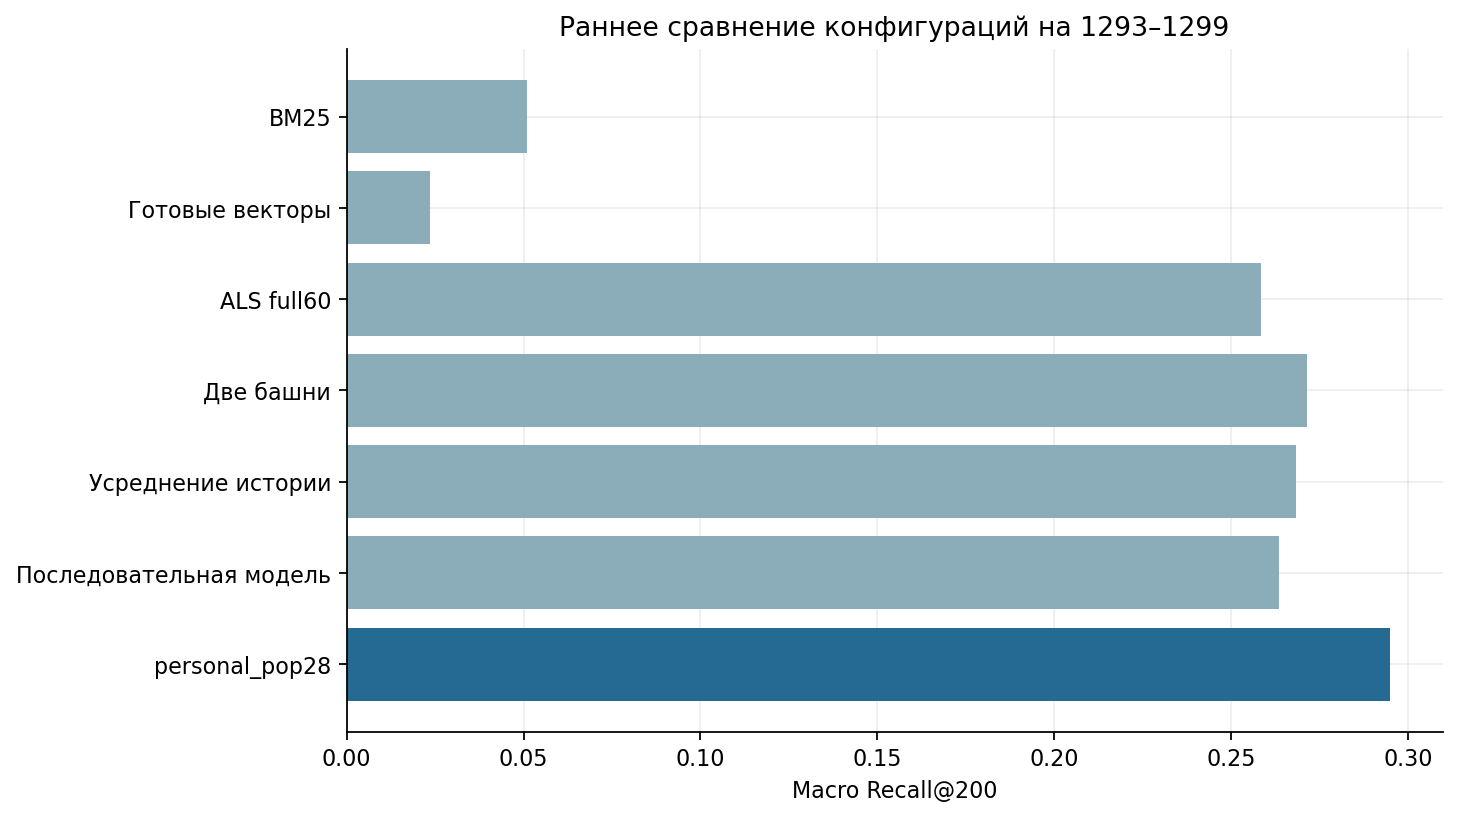

,method,recall_reachable@200,recall_all@200,ndcg@200
0,bm25_strong300,0.050890,0.048882,0.020292
1,provided_content,0.023637,0.022738,0.011662
2,als_full60,0.258313,0.248909,0.081926
3,tower8_raw,0.271460,0.260222,0.079365
4,prefix_pool,0.268336,0.257330,0.085295
5,sasrec_like,0.263624,0.252961,0.094686
6,personal_pop28,0.295046,0.284171,0.112669


In [5]:
comparison = read('closing_checks_20261107__development_common_pop28.csv')
labels = {'bm25_strong300':'BM25', 'provided_content':'Готовые векторы', 'als_full60':'ALS full60',
          'tower8_raw':'Две башни', 'prefix_pool':'Усреднение истории', 'sasrec_like':'Последовательная модель', 'personal_pop28':'personal_pop28'}
ylabels = [labels.get(x,x) for x in comparison.method]
fig, ax = plt.subplots(figsize=(9,5))
colors = ['#246A92' if x == 'personal_pop28' else '#8AADB9' for x in comparison.method]
ax.barh(ylabels, comparison['recall_reachable@200'], color=colors)
ax.invert_yaxis()
ax.set(xlabel='Macro Recall@200', title='Раннее сравнение конфигураций на 1293–1299')
save_figure(fig, figures / 'main_methods.png')
plt.show()
display(comparison[['method','recall_reachable@200','recall_all@200','ndcg@200']])

## Длина профиля ALS

При фиксированных товарных факторах заменяем последние 50 событий всей историей за 60 дней. Пользовательский вектор пересчитывается по новому профилю.

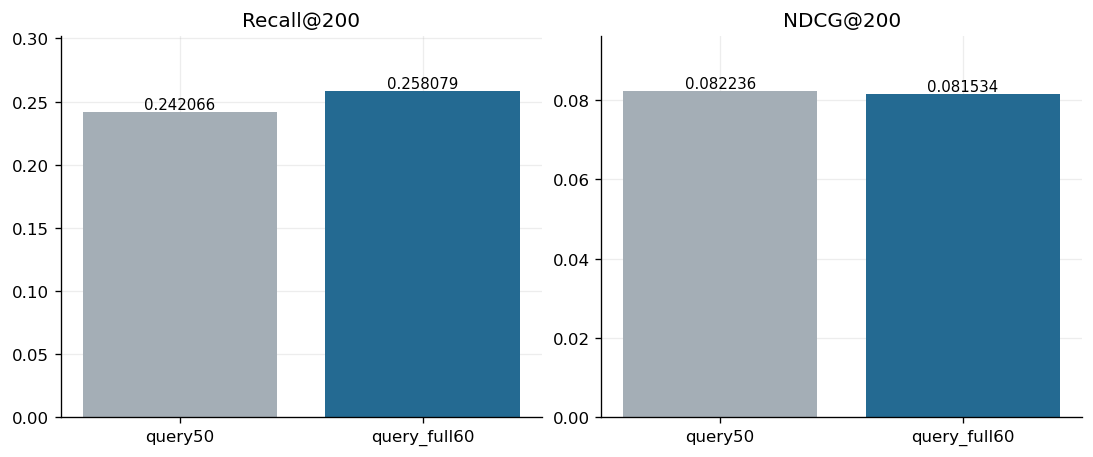

,method,recall_reachable@200,ndcg@200,own_minus_shuffled,profile_nnz
0,query50,0.242066,0.082236,0.044742,2312004
1,query_full60,0.258079,0.081534,0.053077,7182223


In [6]:
profiles = read('profile_audit_20261104__comparison.csv')
fig, axes = plt.subplots(1,2,figsize=(9,3.7))
for ax, metric, title in zip(axes,['recall_reachable@200','ndcg@200'],['Recall@200','NDCG@200']):
    ax.bar(profiles.method, profiles[metric], color=['#A4AEB6','#246A92'])
    ax.set(title=title, ylim=(0,float(profiles[metric].max())*1.17))
    for idx,value in enumerate(profiles[metric]):
        ax.text(idx,value,f'{value:.6f}',ha='center',va='bottom',fontsize=9)
save_figure(fig, figures / 'als_query_profile.png')
plt.show()
display(profiles[['method','recall_reachable@200','ndcg@200','own_minus_shuffled','profile_nnz']])

С полным профилем Recall вырос с 0,2421 до 0,2581. NDCG снизился с 0,0822 до 0,0815.

## Расширение обучения

Сравниваем прежнюю аудиторию, всех дополнительных пользователей и допуск по strong-активности. Пользователи оценки, каталог и цели внутри сравнения остаются прежними.

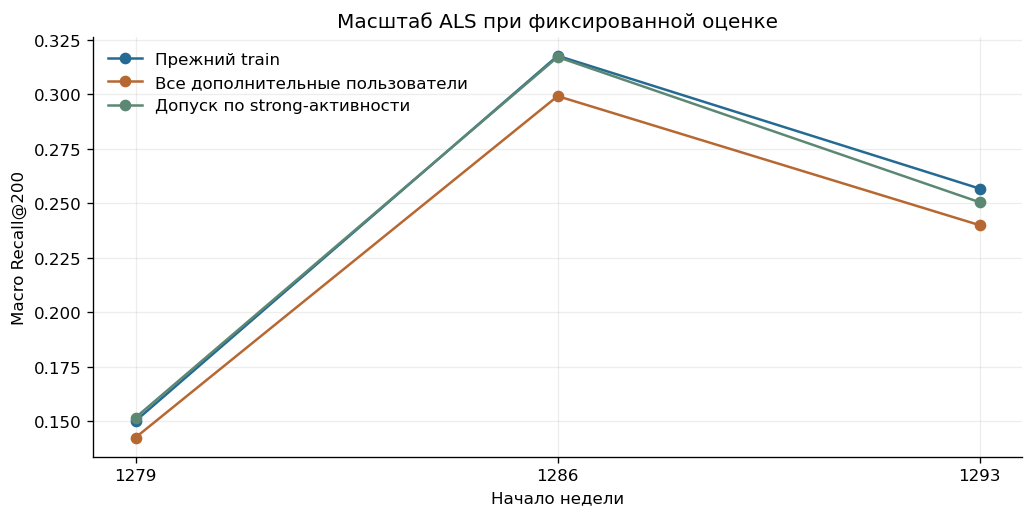

In [7]:
all_users = read('expanded_als_20261105__scale_comparison.csv')
admitted = read('strong_admission_als_20261105__population_comparison.csv')
a = all_users[all_users.method == 'als_full60_pop28'].drop_duplicates('anchor').sort_values('anchor')
s = admitted[admitted.method == 'als_full60_pop28'].sort_values('anchor')
fig, ax = plt.subplots(figsize=(8.5,4.2))
ax.plot(a.anchor, a.old_mean, 'o-', label='Прежний train', color='#246A92')
ax.plot(a.anchor, a['mean'], 'o-', label='Все дополнительные пользователи', color='#B76832')
ax.plot(s.anchor, s['mean'], 'o-', label='Допуск по strong-активности', color='#5C8873')
ax.set(xticks=a.anchor, xlabel='Начало недели', ylabel='Macro Recall@200', title='Масштаб ALS при фиксированной оценке')
ax.legend(frameon=False)
save_figure(fig, figures / 'als_population.png')
plt.show()

## Суточная агрегация и давность

Два отдельных опыта: согласование агрегации запросного профиля ALS с обучением и затухание личной частоты с полураспадом 14 дней.

In [8]:
aggregation = read('focused_hypotheses_20261107__aggregation_summary.csv')
decay = read('focused_hypotheses_20261107__decay_summary.csv')
display(aggregation[aggregation.metric == 'recall_reachable@200'][['anchor','family','current','daily','delta','low95','high95']])
display(decay[decay.metric.isin(['recall_reachable@200','ndcg@200'])])
assert np.allclose(decay.loc[decay.metric == 'recall_reachable@200','delta'],0)

,anchor,family,current,daily,delta,low95,high95
0,1279,als,0.150003,0.150077,0.000074,-0.000478,0.000648
2,1279,fusion,0.192598,0.192498,-0.000100,-0.000288,0.000065
4,1286,als,0.317627,0.318022,0.000395,-0.000592,0.001384
6,1286,fusion,0.430187,0.430061,-0.000125,-0.000408,0.000124
8,1293,als,0.256639,0.256182,-0.000457,-0.001516,0.000626
10,1293,fusion,0.304724,0.305189,0.000465,0.000022,0.000941


,anchor,metric,current,half14,delta,low95,high95,paired_users,bootstrap_repetitions
2,1279,recall_reachable@200,0.191942,0.191942,0.000000,0.000000,0.000000,9749,2000
3,1279,ndcg@200,0.059961,0.060731,0.000770,0.000464,0.001091,9749,2000
6,1286,recall_reachable@200,0.430761,0.430761,0.000000,0.000000,0.000000,6278,2000
7,1286,ndcg@200,0.129335,0.130780,0.001445,0.000970,0.001952,6278,2000
10,1293,recall_reachable@200,0.295046,0.295046,0.000000,0.000000,0.000000,4319,2000
11,1293,ndcg@200,0.112669,0.112209,-0.000460,-0.001408,0.000488,4319,2000


## Вывод

personal_pop28 оказался сильнее recent на трёх периодах. Полный профиль ALS повысил Recall, но увеличение обучающей аудитории не дало устойчивой прибавки. Подробные результаты — в README.